# Planta Física: aprendemos algoritmos genéticos con cuatro decisiones

MA2015.201 · Marzo de 2025 · Una libreta acumulativa.

Construimos un modelo, seguimos una generación y comparamos dos configuraciones pequeñas. Conserva aquí los cálculos, el código y la interpretación de tu equipo.

- **Grupo:** 201
- **Equipo:** 9
- **Integrantes:** Sebastián Ángel Pedraza, David Leonardo García Hernández & Jorge Eduardo Osornio Vázquez

# 1. Definimos el problema

Asignamos una fracción de agua tratada a cada edificio para reducir el agua potable. Usamos demandas agregadas reales de marzo de 2025: Aulas 1 = 847, Biblioteca = 462, Cedetec = 284.21 y Aulas 2 = 683 m³. Conservamos ese orden. Los cuatro registros no tienen banderas de imputación, cero ni anomalía.

Adoptamos 1,410 m³ como **capacidad didáctica**, tomada de la calibración docente existente; no es una capacidad confirmada por el socio. También tratamos los límites por edificio como supuestos didácticos.

Codificamos $k=(k_1,k_2,k_3,k_4)$ con enteros: $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$. Interpretamos $x_i=k_i/10$. Por ejemplo, el gen 6 representa 60% de reúso. Hay $9\times9\times7\times9=5103$ combinaciones; exploramos algunas mediante el algoritmo genético.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## Investigación

**(a) Decisión física y significado de los genes.** Para cada edificio decidimos qué porcentaje de su demanda mensual cubrimos con agua tratada (reúso) mientras que el resto se cubriría con agua potable. Los datos que permanecen fijos son las cuatro demandas mensuales y una única capacidad didáctica de la planta, \(C=1410\) m³, compartida entre los cuatro edificios. La restricción se aplica al volumen tratado total: \(\sum_i T_i\le C\). Un candidato es un cromosoma $k=(k_1,k_2,k_3,k_4)$ de cuatro genes enteros, uno por edificio:

| Posición | Gen | Edificio | Qué representa |
|---|---|---|---|
| 1 | $k_1$ | Aulas 1 | nivel de reúso de Aulas 1 |
| 2 | $k_2$ | Biblioteca | nivel de reúso de Biblioteca |
| 3 | $k_3$ | Cedetec | nivel de reúso de Cedetec |
| 4 | $k_4$ | Aulas 2 | nivel de reúso de Aulas 2 |

Distinguimos tres cantidades: el **nivel** $k_i$ (entero, sin unidades), la **fracción** $x_i=k_i/10$ (sin unidades) y el **volumen** $T_i=D_i x_i$ (en m³).

**(b) Orden, enteros, dominios y conversión.** Siempre nos quedamos con el mismo orden: Aulas 1, Biblioteca, Cedetec, Aulas 2. Cada gen es un entero y su dominio es $k_1,k_2,k_4\in\{0,\ldots,8\}$ y $k_3\in\{0,\ldots,6\}$ (esto porque Cedetec siempre va a ser hasta el 60% y por ende nunca va a tener el nivel 7 ni 8). Cada nivel vale diez puntos escritos en porcentaje: $x_i=k_i/10$ y su porcentaje sería $100x_i$. Por ejemplo, $k_i=6$ da $x_i=0.60$, sería el 60 % de la demanda del edificio. Hay $9\times9\times7\times9=5103$ combinaciones posibles. Esta cuenta de 9 es porque $k_n$ puede tomar valores de 0 a 8, en el caso de Cedetec, $k_n$ puede tomar valores de 0 a 6. Un cromosoma con valores fuera del dominio o no enteros se rechaza.

**(c) Demandas, mes, unidades y procedencia.** Las demandas que usamos pertenecen al archivo de $consumo_agua_2023_2026.csv$, específicamente los cuatro registros de  **marzo de 2025**, en m³:

| Edificio | $D_i$ (m³, marzo 2025) |
|---|---|
| Aulas 1 | 847.00 |
| Biblioteca | 462.00 |
| Cedetec | 284.21 |
| Aulas 2 | 683.00 |
| **Total $Q$** | **2276.21** |

Cabe destacar que los cuatro registros no tienen banderas de imputación, cero ni anomalía. Son datos **observados**.

**(d) Objetivo, fórmulas y dirección de la aptitud.**

$$T_i = D_i\frac{k_i}{10},\qquad P_i = D_i - T_i,\qquad T=\sum_{i=1}^{4}T_i,\qquad P=Q-T,\qquad E=\max(0,\,T-C).$$

$T_i$ y $P_i$ son los volúmenes **tratado** y **potable** de cada edificio; $T$ y $P$ son los totales y $E$ es el exceso de capacidad (todos están en m³). **Minimizamos el agua potable $P$**, el cual está sujeto a los dominios y a $T\le C$, porque cada m³ potable que sustituimos por agua tratada es un m³ potable que no se consume. Después ordenamos a los candidatos con una aptitud que no incluye unidades:

$$F(k)=\begin{cases}P/Q, & T\le C \quad(\text{factible}),\\[2pt] 1+E/C, & T>C \quad(\text{infactible}).\end{cases}$$

**Tener una menor aptitud es mejor.** Un candidato factible tiene $F\le 1$ (menos agua potable = menor $F$); uno infactible tiene $F>1$, así que siempre va a quedar peor que cualquier factible. Comprobamos la capacidad con tolerancia numérica: un candidato cumple cuando $E\le10^{-8}$ m³.

**(e) Capacidad, máximos didácticos y alcance.** La capacidad $C=1410$ m³ y los máximos de reúso (80%, 80%, 60%, 80%) son **supuestos didácticos** tomados de la calibración del profesor, los cuales no representan la capacidad real de la planta. Las demandas sí son consumos observados. El alcance del modelo se limita a comparar asignaciones mensuales de agua tratada para cuatro edificios, usando las demandas observadas de marzo de 2025 y supuestos didácticos de capacidad y límites de reúso. No evalúa la calidad del agua, la infraestructura de distribución ni la variación temporal de la demanda; por ello, sus resultados no constituyen una recomendación hidráulica o sanitaria validada.

# 2. Calculamos agua y aptitud

Definimos agua tratada $T=\sum_iD_i k_i/10$, agua potable $P=\sum_iD_i-T$ y exceso $E=\max(0,T-C)$. Minimizamos $P$ sujeto al dominio y $T\le C$.

Ordenamos candidatos con $F=P/\sum D_i$ si son factibles y $F=1+E/C$ si exceden la capacidad. **Menor aptitud es mejor.** Una solución factible tiene $F\le1$; una infactible tiene $F>1$. Usamos tolerancia numérica de $10^{-8}$ m³.

Antes de ejecutar, calcula a mano $k=(6,6,6,6)$: $T=0.6(2276.21)=1365.726$, $P=910.484$, $E=0$, $F=0.4$. Explica por qué cumple la capacidad y qué unidad tiene cada resultado.

In [2]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

Comprueba tres candidatos: cero reúso, 60% uniforme y máximos del dominio. Distingue cumplir el dominio de cumplir la capacidad. Las claves `treated`, `potable`, `excess`, `feasible` y `fitness` corresponden a $T$, $P$, $E$, factibilidad y $F$.

In [3]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


Interpretamos: el plan máximo usa 1764.126 m³ tratados, excede la capacidad en 354.126 m³ y obtiene $F>1$. Aunque reduce más el agua potable, lo descartamos por infactible. Conserva el cálculo manual y la explicación de tu equipo como evidencia de Investigación.

## Cálculo manual del candidato $k=(6,6,6,6)$

Elegimos $k=(6,6,6,6)$. Es válido: $6\le8$ en Aulas 1, Biblioteca y Aulas 2, y $6\le6$ en Cedetec y todos son enteros. Con $x_i=6/10=0.6$:

| Edificio | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i$ (m³) | $P_i$ (m³) |
|---|---|---|---|---|---|
| Aulas 1 | 847.00 | 6 | 0.6 | 508.200 | 338.800 |
| Biblioteca | 462.00 | 6 | 0.6 | 277.200 | 184.800 |
| Cedetec | 284.21 | 6 | 0.6 | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 6 | 0.6 | 409.800 | 273.200 |

**Hacemos los cálculos manuales para comprobar.**

- $T_1=847\times0.6=508.2$ m³; $P_1=847-508.2=338.8$ m³
- $T_2=462\times0.6=277.2$ m³; $P_2=462-277.2=184.8$ m³
- $T_3=284.21\times0.6=170.526$ m³; $P_3=284.21-170.526=113.684$ m³
- $T_4=683\times0.6=409.8$ m³; $P_4=683-409.8=273.2$ m³

**Totales.**

- $T=508.2+277.2+170.526+409.8=1365.726$ m³
- $P=338.8+184.8+113.684+273.2=910.484$ m³

**Comprobaciones.** En total, $T+P=1365.726+910.484=2276.21=Q$ m³ ✓.

**Exceso y factibilidad.** $E=\max(0,\,1365.726-1410)=\max(0,\,-44.274)=0$ m³. Como tenemos que $T\le C$ (con 44.274 m³ de espacio sobrante) y $E\le10^{-8}$ m³, el candidato es **factible**.

**Aptitud.** Al ser factible usamos la rama $F=P/Q$:

$$F=\frac{910.484}{2276.21}=0.4\ \text{(sin unidades)}.$$

Coincide con $1-0.6$, porque con 60 % de reúso uniforme $P/Q=1-0.6$.

In [4]:
genes = np.array([6, 6, 6, 6], dtype=int)
resultado = evaluate(genes)

manual = {
    "treated": 1365.726,
    "potable": 910.484,
    "excess": 0.0,
    "feasible": True,
    "fitness": 0.4
}

print("Genes:", genes)
print("Resultado de evaluate:", resultado)
print("\nDiferencia = evaluate - manual")
print(f"{'Clave':<10} {'Manual':>16} {'evaluate':>16} {'Diferencia':>16}")

for clave in manual:
    if clave == "feasible":
        diferencia = (
            "Coincide" if resultado[clave] == manual[clave]
            else "No coincide"
        )
        print(
            f"{clave:<10} {str(manual[clave]):>16} "
            f"{str(resultado[clave]):>16} {diferencia:>16}"
        )
    else:
        print(
            f"{clave:<10} {manual[clave]:>16.12f} "
            f"{resultado[clave]:>16.12f} "
            f"{resultado[clave] - manual[clave]:>16.3e}"
        )

Genes: [6 6 6 6]
Resultado de evaluate: {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}

Diferencia = evaluate - manual
Clave                Manual         evaluate       Diferencia
treated    1365.726000000000 1365.726000000000       -2.274e-13
potable    910.484000000000 910.484000000000        1.137e-13
excess       0.000000000000   0.000000000000        0.000e+00
feasible               True             True         Coincide
fitness      0.400000000000   0.400000000000        5.551e-17


## Comparación del cálculo manual con `evaluate`

Los cinco resultados coinciden con el cálculo manual, salvo diferencias numéricas del orden de $10^{-13}$ en los volúmenes y $10^{-17}$ en la aptitud, debidas a la representación de punto flotante. La factibilidad coincide: `True`.

En los cálculos manuales presentamos los volúmenes con tres decimales y la aptitud con seis decimales. En la tabla de comparación mostramos los valores numéricos con doce decimales y sus diferencias en notación científica para hacer visibles los errores de punto flotante. Conservamos la precisión completa durante los cálculos. La factibilidad se determina con la tolerancia de $10^{-8}$ m³ definida en `evaluate`.

## Cálculo e interpretación del candidato máximo $k=(8,8,6,8)$

**Dominios y fracciones de reúso.**

Todos los genes son enteros y respetan sus dominios:

- Aulas 1, Biblioteca y Aulas 2 permiten niveles de 0 a 8.
- Cedetec permite niveles de 0 a 6.

Las fracciones de reúso son:

$$
x=\frac{k}{10}=(0.8,0.8,0.6,0.8).
$$

**Cálculos por edificio.**

Calculamos el volumen tratado y el volumen potable mediante:

$$
T_i=D_i x_i,
\qquad
P_i=D_i-T_i.
$$

| Edificio | Demanda $D_i$ (m³) | Gen $k_i$ | Fracción $x_i$ | Tratada $T_i$ (m³) | Potable $P_i$ (m³) |
|---|---:|---:|---:|---:|---:|
| Aulas 1 | 847.00 | 8 | 0.8 | 677.600 | 169.400 |
| Biblioteca | 462.00 | 8 | 0.8 | 369.600 | 92.400 |
| Cedetec | 284.21 | 6 | 0.6 | 170.526 | 113.684 |
| Aulas 2 | 683.00 | 8 | 0.8 | 546.400 | 136.600 |
| **Total** | **2276.21** | — | — | **1764.126** | **512.084** |

**Totales y comprobación.**

$$
T=677.600+369.600+170.526+546.400=1764.126\ \text{m}^3.
$$

$$
P=169.400+92.400+113.684+136.600=512.084\ \text{m}^3.
$$

La suma de los volúmenes tratado y potable coincide con la demanda total:

$$
T+P=1764.126+512.084=2276.210=Q\ \text{m}^3.
$$

**Exceso y factibilidad.**

La capacidad didáctica es una sola para toda la planta:

$$
C=1410\ \text{m}^3.
$$

El exceso es:

$$
E=\max(0,T-C)
=\max(0,1764.126-1410)
=354.126\ \text{m}^3.
$$

Aunque el candidato respeta los dominios de los genes, es **infactible** porque el volumen tratado total supera la capacidad de la planta. Además, el exceso es mayor que la tolerancia numérica de $10^{-8}$ m³.

**Rama de aptitud.**

Al ser infactible, recibe la rama:

$$
F=1+\frac{E}{C}
=1+\frac{354.126}{1410}
\approx1.251153.
$$

La aptitud no tiene unidades. Como una menor aptitud es mejor, este candidato queda peor que cualquier candidato factible, aunque utilice menos agua potable.

**Redondeo.**

Presentamos los volúmenes con tres decimales y la aptitud con seis decimales. Conservamos la precisión completa durante los cálculos.

In [5]:
genes_maximos = np.array([8, 8, 6, 8], dtype=int)
print("Genes:", genes_maximos)
print("Resultado de evaluate:", evaluate(genes_maximos))

Genes: [8 8 6 8]
Resultado de evaluate: {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


# 3. Generamos una población

Una población es una lista de candidatos. Muestreamos cada gen dentro de su dominio, incluidos los extremos. El muestreo no garantiza capacidad: la función de aptitud ordena también los candidatos infactibles. Fijamos la semilla para reproducir esta demostración.

In [6]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


# 4. Seleccionamos padres mediante torneo

Tomamos dos candidatos distintos al azar y elegimos el de menor $F$. Repetimos para elegir otro padre; un mismo individuo puede ganar varios torneos. La selección favorece aptitudes bajas sin ordenar siempre toda la población. Devolvemos una copia para proteger el original.

In [7]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


# 5. Combinamos información con cruza de un punto

Elegimos un corte entre posiciones y tomamos el inicio del primer padre y el final del segundo. Conservamos la posición de cada edificio. Con padres $(6,6,6,6)$ y $(8,2,4,3)$ y corte 2 obtenemos $(6,6,4,3)$. La cruza preserva dominios, pero puede producir exceso de capacidad.

In [8]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


# 6. Introducimos variación con mutación

Aplicamos la probabilidad a **cada gen**, no al cromosoma completo. Cada gen elegido sube o baja un nivel válido. En cero sólo subimos; en el máximo sólo bajamos. Con $p=0.25$ y cuatro genes, esperamos un gen seleccionado por hijo en promedio, no exactamente uno. La mutación puede mejorar o empeorar la aptitud.

In [9]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


# 7. Reemplazamos la población y conservamos una élite

Copiamos el mejor individuo sin modificarlo y llenamos las posiciones restantes con hijos. Mantenemos el tamaño de la población. El elitismo evita perder el mejor valor de aptitud; no demuestra que ya encontramos el óptimo. Con una copia independiente, mutar un hijo no modifica al padre ni a la élite.

In [10]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


# 8. Cerramos el ciclo

Inicializamos, evaluamos y repetimos selección, cruza, mutación y reemplazo durante un número fijo de generaciones. Registramos el mejor $F$ inicial y después de cada generación. Con 20 generaciones obtenemos 21 valores, incluido el estado inicial. No esperamos una mejora en cada paso.

In [11]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

# 9. Ejecuta una configuración base y una variación

Usa 20 individuos, 20 generaciones y semilla 42. En la variación cambia únicamente la probabilidad de mutación de 0.25 a 0.50. Conserva datos, dominios, capacidad y los demás parámetros. Esta comparación describe dos ejecuciones; no demuestra superioridad general de una configuración.

In [12]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


# 10. Visualizamos e interpretamos

Leemos el eje horizontal como generación y el vertical como mejor aptitud. Una caída representa mejora; una meseta indica que conservamos el mejor valor. Relacionamos siempre la gráfica con factibilidad y volúmenes. Una gráfica descendente por sí sola no prueba validez física.

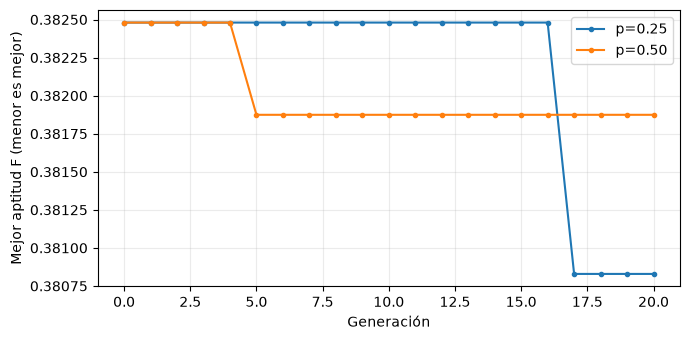

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generación', ylabel='Mejor aptitud F (menor es mejor)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

Conserva la interpretación de tu equipo en una celda: identifica el parámetro cambiado; compara el mejor $F$, el agua potable y la factibilidad; explica una meseta o mejora; y delimita lo que puedes concluir de dos ejecuciones. Si los resultados coinciden, explica esa coincidencia con la misma validez. La variación no necesita ganar.

# 11. Comprueba reproducción

Repite la configuración base con la misma semilla y comprueba igualdad de genes e historia. Reinicia el kernel y ejecuta de arriba abajo para descartar dependencias de ejecuciones previas. Esta repetición es una comprobación técnica, no una tercera configuración experimental.

In [14]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproducción y elitismo comprobados.')

Reproducción y elitismo comprobados.


# 12. Conserva evidencia en la misma libreta

- **Investigación (15%)**: formulación y supuestos (60/100); cálculo manual y contraste con el evaluador (40/100).
- **Desarrollo (15%)**: ciclo y operadores funcionales (70/100); una ejecución reproducible e interpretada (30/100).
- **Entrega final (30%)**: explicación de una generación (40/100); dos configuraciones y gráfica (35/100); interpretación física y límites (25/100).

En la entrega final reutiliza las secciones anteriores y añade la explicación de tu equipo. Identifica la base común y cualquier cambio propio. Las funciones adicionales no son necesarias para obtener 100. Conserva los archivos de entorno proporcionados junto a la libreta. La evaluación conjunta del código aporta 10% y el examen individual de artículos 30%. Consulta niveles y fechas en la [guía](guia_reto_planta_fisica.pdf).

# Procedencia y entorno

Usamos `assets/kit/datos/consumo_agua_2023_2026.csv` y `assets/kit/parametros_reto.csv` del repositorio técnico MA2015-Planta-Fisica, filtrados a marzo de 2025. La metadata conserva los cuatro registros y los hashes de las fuentes completas. El caso mensual y el código son autónomos.

Con Python 3.12–3.14 y los archivos proporcionados, prepara el entorno con `uv sync --locked` y abre Jupyter con `uv run jupyter lab`. NumPy realiza los cálculos y Matplotlib dibuja la gráfica. Los resultados representan este modelo didáctico, no una recomendación hidráulica o sanitaria validada.

# Desarrollo: modificación justificada de la mutación

## Base, limitación e hipótesis

La versión base es el algoritmo definido anteriormente mediante `tournament`, `crossover`, `mutate`, `next_generation` y `run_ga`.

La base selecciona padres mediante torneos de dos candidatos, combina sus genes mediante cruza de un punto y aplica mutación por gen. Después reemplaza la población y conserva una copia del mejor individuo como élite. La evaluación utiliza `evaluate`; una menor aptitud es mejor.

**Limitación identificada.** La mutación base desplaza cada gen seleccionado solamente un nivel hacia arriba o hacia abajo. Alcanzar niveles distantes mediante mutación puede requerir varios cambios sucesivos.

**Cambio propuesto.** Modificamos únicamente la mutación: cada gen seleccionado toma otro entero de su dominio con igual probabilidad. El nuevo valor debe ser distinto del anterior. Cedetec conserva su dominio de 0 a 6 y los demás edificios conservan sus dominios de 0 a 8.

**Hipótesis.** Permitir saltos mayores podría explorar asignaciones diferentes y encontrar un candidato factible con menor consumo de agua potable en 20 generaciones.

Los saltos también pueden deteriorar candidatos o producir exceso de capacidad. Por ello, una mejora no está garantizada y se interpretará el resultado obtenido aunque sea igual o peor.

La variante se identifica mediante `mutate_reset`, `next_generation_reset` y `run_ga_reset`. Las dos últimas funciones conectan la nueva mutación con el ciclo; conservan el comportamiento de los demás operadores.

La comparación anterior entre probabilidades 0.25 y 0.50 se conserva como un experimento distinto. En esta estapa (Desarrollo) comparamos base y variante con probabilidad 0.25 en ambas.

In [15]:
def mutate_reset(child: np.ndarray, probability: float,
                 rng: np.random.Generator) -> np.ndarray:
    """Replace each selected gene with a different valid integer."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    evaluate(child)  # Reject invalid genes without rounding or repairing them.
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            options = [
                value for value in range(int(limit) + 1)
                if value != result[i]
            ]
            result[i] = rng.choice(options)
    return result

In [16]:
def next_generation_reset(population: list, probability: float,
                          rng: np.random.Generator) -> list:
    """Preserve one elite and use the reset mutation for offspring."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate_reset(child, probability, rng))
    return replacement


def run_ga_reset(population_size: int = 20, generations: int = 20,
                 mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run the variant while retaining the base configuration rules."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")

    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]

    for _ in range(generations):
        population = next_generation_reset(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))

    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(
        genes=best,
        metrics=evaluate(best),
        history=np.array(history)
    )

## Comparación controlada

| Condición | Base | Variante |
|---|---|---|
| Población | 20 individuos | 20 individuos |
| Generaciones | 20 | 20 |
| Semilla inicial | 42 | 42 |
| Probabilidad de mutación | 0.25 por gen | 0.25 por gen |
| Selección | Torneo de dos | Torneo de dos |
| Cruza | Un punto | Un punto |
| Mutación | Un nivel vecino válido | Otro nivel válido del dominio |
| Reemplazo | Generacional, con una élite | Generacional, con una élite |
| Evaluación | `evaluate` | `evaluate` |

Ambas ejecuciones inicializan su propio generador con semilla 42 y utilizan la misma regla para crear la población inicial. No se reutiliza el estado aleatorio dejado por otra ejecución.

Conservamos las demandas de marzo de 2025, el orden de los edificios, los dominios, la capacidad conjunta $C=1410$ m³ y la tolerancia de $10^{-8}$ m³.

El único cambio experimental es el mecanismo de mutación. Mantener la semilla no implica que ambas versiones consuman números aleatorios de manera idéntica después del cambio de operador.

Presentamos los volúmenes con tres decimales y la aptitud con seis. Los cálculos y las comprobaciones conservan la precisión completa.

In [17]:
from IPython.display import display, Markdown

DESARROLLO_CONFIG = dict(
    population_size=20,
    generations=20,
    mutation_probability=0.25,
    seed=42
)

desarrollo_base = run_ga(**DESARROLLO_CONFIG)
desarrollo_variante = run_ga_reset(**DESARROLLO_CONFIG)

def development_rows(result):
    genes = result["genes"]
    metrics = evaluate(genes)
    valid_domains = (
        genes.shape == (4,)
        and np.issubdtype(genes.dtype, np.integer)
        and bool(np.all((genes >= 0) & (genes <= LIMITS)))
    )
    return [
        str(tuple(int(value) for value in genes)),
        f"{metrics['treated']:.3f}",
        f"{metrics['potable']:.3f}",
        f"{metrics['fitness']:.6f}",
        f"{metrics['excess']:.3f}",
        "Sí" if valid_domains else "No",
        "Sí" if metrics["feasible"] else "No"
    ]

labels = [
    "Cromosoma final",
    "Agua tratada T (m³)",
    "Agua potable P (m³)",
    "Aptitud F",
    "Exceso E (m³)",
    "Dominios válidos",
    "Cumple capacidad"
]
table = ["| Medida | Base | Variante |", "|---|---:|---:|"]
for label, base_value, variant_value in zip(
    labels,
    development_rows(desarrollo_base),
    development_rows(desarrollo_variante)
):
    table.append(f"| {label} | {base_value} | {variant_value} |")

print("Configuración común:", DESARROLLO_CONFIG)
display(Markdown("\n".join(table)))

if (desarrollo_base["metrics"]["feasible"]
        and desarrollo_variante["metrics"]["feasible"]):
    difference = (
        desarrollo_variante["metrics"]["potable"]
        - desarrollo_base["metrics"]["potable"]
    )
    print(f"P variante - P base = {difference:.3f} m³")
    print("Un valor positivo indica un mayor consumo potable en la variante.")
else:
    print("La comparación de mejora debe considerar primero la factibilidad.")

Configuración común: {'population_size': 20, 'generations': 20, 'mutation_probability': 0.25, 'seed': 42}


| Medida | Base | Variante |
|---|---:|---:|
| Cromosoma final | (7, 4, 3, 8) | (6, 6, 5, 7) |
| Agua tratada T (m³) | 1409.363 | 1405.605 |
| Agua potable P (m³) | 866.847 | 870.605 |
| Aptitud F | 0.380829 | 0.382480 |
| Exceso E (m³) | 0.000 | 0.000 |
| Dominios válidos | Sí | Sí |
| Cumple capacidad | Sí | Sí |

P variante - P base = 3.758 m³
Un valor positivo indica un mayor consumo potable en la variante.


In [18]:
# Check mutation behavior and protect the original candidate.
probe = np.array([6, 6, 6, 6], dtype=int)
original_probe = probe.copy()

unchanged = mutate_reset(probe, 0.0, np.random.default_rng(42))
changed = mutate_reset(probe, 1.0, np.random.default_rng(42))

np.testing.assert_array_equal(unchanged, probe)
np.testing.assert_array_equal(probe, original_probe)
assert np.all(changed != probe)
assert not np.shares_memory(changed, probe)
evaluate(changed)

# Confirm that reset mutation can produce jumps greater than one level.
jump_rng = np.random.default_rng(42)
samples = [mutate_reset(probe, 1.0, jump_rng) for _ in range(20)]
assert any(np.any(np.abs(sample - probe) > 1) for sample in samples)

# Invalid chromosomes must be rejected, not silently corrected.
for invalid in [
    np.array([8, 8, 7, 8]),
    np.array([6.0, 6.0, 6.0, 6.0])
]:
    try:
        mutate_reset(invalid, 0.25, np.random.default_rng(42))
    except ValueError:
        pass
    else:
        raise AssertionError("An invalid chromosome was accepted.")

# Check both complete cycles, including an identical initial population.
initial_populations = []
for step in (next_generation, next_generation_reset):
    rng_check = np.random.default_rng(DESARROLLO_CONFIG["seed"])
    population = [
        random_individual(rng_check)
        for _ in range(DESARROLLO_CONFIG["population_size"])
    ]
    initial_populations.append(np.array(population))

    for _ in range(DESARROLLO_CONFIG["generations"]):
        previous = [individual.copy() for individual in population]
        elite = min(previous, key=lambda x: evaluate(x)["fitness"]).copy()
        replacement = step(
            population,
            DESARROLLO_CONFIG["mutation_probability"],
            rng_check
        )
        assert len(replacement) == DESARROLLO_CONFIG["population_size"]
        assert any(np.array_equal(individual, elite) for individual in replacement)
        assert all(
            not np.shares_memory(new, old)
            for new in replacement for old in population
        )
        for before, after in zip(previous, population):
            np.testing.assert_array_equal(before, after)
        for individual in replacement:
            evaluate(individual)  # Checks integer type, shape and domains.
        assert min(evaluate(x)["fitness"] for x in replacement) <= (
            evaluate(elite)["fitness"] + 1e-12
        )
        population = replacement

np.testing.assert_array_equal(*initial_populations)
print("Comprobado: misma población inicial, mutación válida,")
print("población constante, padres intactos y élite protegida en ambas versiones.")

Comprobado: misma población inicial, mutación válida,
población constante, padres intactos y élite protegida en ambas versiones.


In [19]:
for label, runner, first_result in [
    ("Base", run_ga, desarrollo_base),
    ("Variante", run_ga_reset, desarrollo_variante)
]:
    repeated_result = runner(**DESARROLLO_CONFIG)
    np.testing.assert_array_equal(
        first_result["genes"], repeated_result["genes"]
    )
    np.testing.assert_array_equal(
        first_result["history"], repeated_result["history"]
    )
    assert first_result["metrics"] == repeated_result["metrics"]
    assert len(first_result["history"]) == (
        DESARROLLO_CONFIG["generations"] + 1
    )
    assert np.all(np.diff(first_result["history"]) <= 1e-12)
    print(f"{label}: genes, medidas e historia reproducidos con semilla 42.")

Base: genes, medidas e historia reproducidos con semilla 42.
Variante: genes, medidas e historia reproducidos con semilla 42.


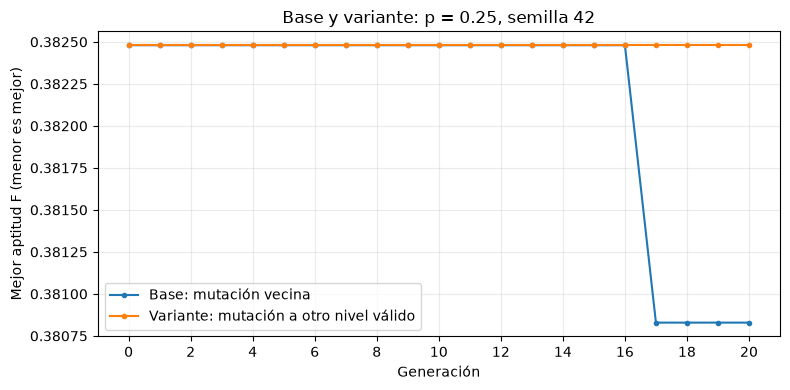

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))

for label, result in [
    ("Base: mutación vecina", desarrollo_base),
    ("Variante: mutación a otro nivel válido", desarrollo_variante)
]:
    ax.plot(
        range(len(result["history"])),
        result["history"],
        marker=".",
        label=label
    )

ax.set(
    title="Base y variante: p = 0.25, semilla 42",
    xlabel="Generación",
    ylabel="Mejor aptitud F (menor es mejor)"
)
ax.set_xticks(range(0, DESARROLLO_CONFIG["generations"] + 1, 2))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Interpretación de los resultados

La base obtiene el cromosoma $(7,4,3,8)$, que asigna fracciones de reúso $(0.7,0.4,0.3,0.8)$ a Aulas 1, Biblioteca, Cedetec y Aulas 2, respectivamente.

La variante obtiene $(6,6,5,7)$, con fracciones $(0.6,0.6,0.5,0.7)$ en el mismo orden. Ambos candidatos respetan los dominios y la capacidad conjunta de la planta.

| Medida | Base | Variante |
|---|---:|---:|
| Agua tratada $T$ (m³) | 1409.363 | 1405.605 |
| Agua potable $P$ (m³) | 866.847 | 870.605 |
| Exceso $E$ (m³) | 0.000 | 0.000 |
| Aptitud $F$ | 0.380829 | 0.382480 |
| Factible | Sí | Sí |

La variante utiliza:

$$
870.605-866.847=3.758\ \text{m}^3
$$

más de agua potable que la base. Como ambos candidatos son factibles, la base presenta el mejor resultado observado: menor consumo potable y menor aptitud.

**Evaluación de la hipótesis.** Esta ejecución no apoya la expectativa de obtener una mejor asignación mediante saltos mayores. La variante permite explorar niveles distantes, pero esa posibilidad no produjo una mejora del candidato final con semilla 42 y 20 generaciones. El resultado no demuestra que este mecanismo de mutación sea inferior en general.

**Alcance.** Una sola semilla permite comparar estas dos ejecuciones, pero no establecer superioridad general ni demostrar que se encontró el óptimo. Los resultados corresponden a cuatro edificios y a las demandas observadas de marzo de 2025, con capacidad y límites de reúso didácticos. No constituyen una recomendación hidráulica o sanitaria validada.

## Registro breve de rotación del equipo

| Entrega | Programación | Revisión | Verificación |
|---|---|---|---|
| Investigación  |  David | Sebas | Jorge |
| Desarrollo  |  Sebas | Jorge | David |
| Final  |  Jorge | David | Sebas |

## Reproducción y entrega

Las funciones base permanecen sin modificaciones. La variante utiliza funciones separadas y el mismo evaluador.

Antes de entregar, reiniciamos el kernel y ejecutamos todas las celdas de arriba abajo. Comprobamos que la comparación y las verificaciones terminan sin errores y conservamos sus salidas.

Entregamos la libreta acumulativa `.ipynb` junto con los archivos proporcionados `pyproject.toml` y `uv.lock`. Las versiones del entorno utilizado se registran en la siguiente celda.

In [21]:
import sys
import platform
import matplotlib

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Intérprete:", sys.executable)
print("Configuración de Desarrollo:", DESARROLLO_CONFIG)

numpy_matches = np.__version__ == "2.5.4"
python_matches = (3, 12) <= sys.version_info[:2] < (3, 15)
print("NumPy coincide con pyproject.toml:", numpy_matches)
print("Python está dentro del intervalo requerido:", python_matches)

if not (numpy_matches and python_matches):
    print(
        "Revisar el entorno antes de entregar: el proyecto requiere "
        "NumPy 2.5.4 y Python >=3.12,<3.15."
    )

Python: 3.12.4
NumPy: 2.5.4
Matplotlib: 3.11.1
Intérprete: /usr/local/bin/python3.12
Configuración de Desarrollo: {'population_size': 20, 'generations': 20, 'mutation_probability': 0.25, 'seed': 42}
NumPy coincide con pyproject.toml: True
Python está dentro del intervalo requerido: True


## Puntos importantes a tener en cuenta

El archivo proporcionado originalmente especificaba NumPy 2.3.5. Para esta entrega cambiamos la dependencia a NumPy 2.5.4 en `pyproject.toml` y actualizamos `uv.lock` para mantener ambos archivos consistentes.

Las modificaciones sugeridas en los comentarios de la primer entrega ya fueron añadidas para esta entrega y cumplen con las especificaciones.

Las ejecuciones de base y variante utilizan el mismo entorno. Este cambio de dependencia no modifica las demandas, los dominios, la capacidad ni las fórmulas del evaluador.